# Logistic Regression Classification with Supermarket Dataset

I will be using the Logistic Regression algorithm to predict whether a supermarket transaction will result in a repeated purchase (`repeated_purchase`). The dataset contains transaction records and features covering customer behavior, pricing, promotions, and shopping habits.

We will be importing the pandas library to read and analyze the file, along with the scikit-learn module for Logistic Regression.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

from sklearn.metrics import ConfusionMatrixDisplay

### Read the csv (comma separated file) using pandas

In [2]:
supermarketData = pd.read_csv("../Data/supermarket_subset.csv")
supermarketData.head()

,transaction_id,transaction_line_id,basket_id,customer_id,store_id,product_id,employee_id,supplier_id,customer_age,customer_gender,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
0,T00021905,TL00021905,B00037526,C00035108,S00000063,P00001069,E00000401,SUP00000036,44,Female,...,7,15.68,-0.49,-0.219,125,47,0.1,-0.131,0.0720,0.0351
1,T00093977,TL00093977,B00028427,C00062754,S00000076,P00004268,E00000491,SUP00000006,43,Male,...,7,21.77,0.57,0.183,910,21,4.9,-0.063,0.0214,0.0594
2,T00074823,TL00074823,B00049794,C00024688,S00000040,P00000513,E00000418,SUP00000047,46,Female,...,16,96.96,3.03,0.500,754,11,4.5,0.396,0.0479,0.0823
3,T00063004,TL00063004,B00039714,C00093668,S00000032,P00004501,E00000230,SUP00000048,43,Female,...,5,27.85,-1.49,-0.268,495,10,6.1,0.218,0.0000,0.0763
4,T00054231,TL00054231,B00046502,C00038252,S00000021,P00001089,E00000478,SUP00000023,62,Other,...,9,149.31,9.23,0.556,441,44,3.0,-0.272,0.0358,0.0710


### Check Dataset Columns and Shape
Let's inspect our column names and overall dataset dimensions. The target variable we want to predict is `repeated_purchase`.
### We can check the different column names in the dataset as follows:

In [3]:

print("Dataset shape (rows, columns):", supermarketData.shape)
supermarketData.columns

Dataset shape (rows, columns): (12000, 323)


Index(['transaction_id', 'transaction_line_id', 'basket_id', 'customer_id',
       'store_id', 'product_id', 'employee_id', 'supplier_id', 'customer_age',
       'customer_gender',
       ...
       'units_sold', 'sales_revenue', 'profit_per_unit', 'profit_margin',
       'sales_rank', 'category_sales_rank', 'product_popularity',
       'product_growth_rate', 'product_return_rate', 'product_stockout_rate'],
      dtype='str', length=323)

### Checking Missing Values
Instead of dropping rows (which would delete the entire dataset), we will inspect null values and let our pipeline handle imputation automatically.

In [4]:
print(f"Total null values in dataset: {supermarketData.isnull().sum().sum()}")

Total null values in dataset: 112463


### Shuffling the Dataset
Shuffling breaks any pre-existing chronological or class-based ordering in the dataset before we split it.

In [5]:
df_randomized = supermarketData.sample(frac=1, random_state=42).reset_index(drop=True)
df_randomized.head()

,transaction_id,transaction_line_id,basket_id,customer_id,store_id,product_id,employee_id,supplier_id,customer_age,customer_gender,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
0,T00091276,TL00091276,B00002389,C00050975,S00000136,P00001004,E00000219,SUP00000003,23,Male,...,2,41.40,12.02,0.581,314,11,6.0,-0.184,0.0142,0.0645
1,T00104846,TL00104846,B00017045,C00085877,S00000067,P00004609,E00000075,SUP00000034,30,Other,...,6,41.82,3.66,0.525,686,23,4.3,0.087,0.0499,0.0202
2,T00109158,TL00109158,B00001015,C00087130,S00000007,P00001305,E00000184,SUP00000041,24,Female,...,8,35.36,2.03,0.459,451,86,4.5,0.021,0.0000,0.0098
3,T00026201,TL00026201,B00040483,C00063513,S00000055,P00003003,E00000004,SUP00000034,19,Male,...,5,31.30,3.34,0.534,98,58,3.8,0.083,0.0122,0.0867
4,T00004242,TL00004242,B00029780,C00103139,S00000192,P00004225,E00000011,SUP00000050,76,Female,...,12,46.56,1.72,0.443,565,16,2.7,0.270,0.0101,0.0217


### Separating Features (X) and Target (y)
We separate our target label (`repeated_purchase`) from all other feature columns.

In [6]:
target_col = 'repeat_purchase'
for col in supermarketData.columns:
    if 'repeat' in col.lower() or 'purchase' in col.lower():
        target_col = col
        break

drop_cols = [target_col,
    'customer_visit_frequency',
    'average_monthly_visits',
    'customer_tenure_months',
    'days_since_last_purchase',
    'average_transaction_value',
    'loyalty_program_member',
    'selling_price',
    'discount_percent',
    'promotion_active',
    'shopping_period'
]

existing_drop_cols = [col for col in drop_cols if col in supermarketData.columns]

X = supermarketData.drop(columns=existing_drop_cols)
y = supermarketData[target_col]

print("Features (X) shape after dropping IDs:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape after dropping IDs: (12000, 312)
Target (y) shape: (12000,)


### Splitting Data into Training and Test Sets
We reserve 20% of the data for testing and 80% for training.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=12, shuffle=True
)

print("Training set shape (X_train):", X_train.shape)
print("Test set shape (X_test):", X_test.shape)

Training set shape (X_train): (9600, 312)
Test set shape (X_test): (2400, 312)


## Logistic Regression Model Pipeline & Training
We set up a preprocessing pipeline using `SimpleImputer` (to fill missing numeric/categorical values) and `StandardScaler` / `OneHotEncoder`, followed by our `LogisticRegression` classifier.

In [8]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

modelPrediction = model.predict(X_test)
print("Model training and prediction completed successfully!")

C:\Users\PHOENIX\AppData\Local\Temp\ipykernel_11792\2245822982.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns


Model training and prediction completed successfully!


## Model Evaluation and Accuracy
We calculate model **accuracy** as the ratio of correct predictions to the total number of predictions, and display the classification report.

$$Accuracy = \frac{\text{Number of correct predictions}}{\text{Total number of predictions}}$$

In [9]:
correct_preds = np.sum(y_test == modelPrediction)
accuracy = correct_preds / modelPrediction.size

print(f"Number of correct predictions: {correct_preds}")
print(f"Total number of predictions: {modelPrediction.size}")
print(f"Accuracy: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, modelPrediction))

Number of correct predictions: 828
Total number of predictions: 2400
Accuracy: 0.3450

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.72      0.63       861
           1       0.19      0.18      0.18       439
           2       0.15      0.14      0.14       339
           3       0.16      0.10      0.12       267
           4       0.15      0.12      0.14       194
           5       0.16      0.12      0.13       136
           6       0.12      0.11      0.11        80
           7       0.11      0.14      0.12        56
           8       0.17      0.11      0.13        28

    accuracy                           0.34      2400
   macro avg       0.20      0.19      0.19      2400
weighted avg       0.31      0.34      0.32      2400



## Visualizing the Model’s Final Results

The charts below summarize the model’s predictions on the test data. The confusion matrix shows how often each `repeated_purchase` class was predicted correctly or misclassified. The bar chart compares the actual and predicted transaction counts for each class.

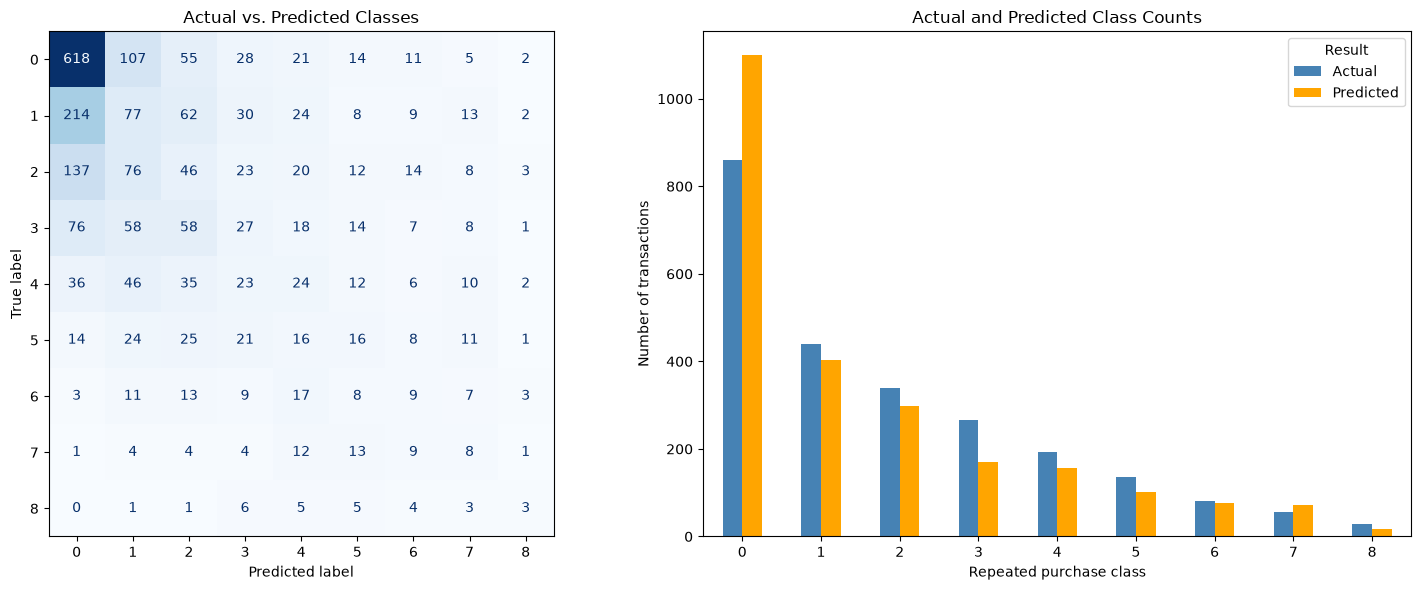

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    modelPrediction,
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)
axes[0].set_title("Actual vs. Predicted Classes")

actual_counts = pd.Series(y_test).value_counts().sort_index()
predicted_counts = pd.Series(modelPrediction).value_counts().sort_index()
class_counts = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": predicted_counts
}).fillna(0)

class_counts.plot(kind="bar", ax=axes[1], color=["steelblue", "orange"])
axes[1].set_title("Actual and Predicted Class Counts")
axes[1].set_xlabel("Repeated purchase class")
axes[1].set_ylabel("Number of transactions")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Result")

plt.tight_layout()
plt.show()